In [1]:

# Week 3: Unsupervised Learning and Clustering Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")
print("Ready to start Customer Segmentation.")


Libraries imported successfully!
Ready to start Customer Segmentation.


In [3]:
# Download the public Mall Customers dataset from a reliable alternative URL
url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
Dataset shape: (200, 5)

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:

# Step 3: Data quality checks

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate Customer IDs:", df["CustomerID"].duplicated().sum())

print("\nGender categories:")
print(df["Gender"].value_counts())

print("\nStatistical summary:")
display(df.describe().round(2))

print("\nDataset shape:", df.shape)


Missing values in each column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Total missing values: 0

Duplicate rows: 0

Duplicate Customer IDs: 0

Gender categories:
Gender
Female    112
Male       88
Name: count, dtype: int64

Statistical summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00



Dataset shape: (200, 5)


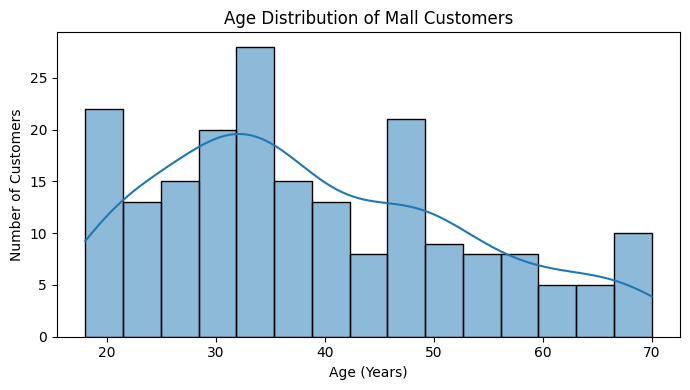

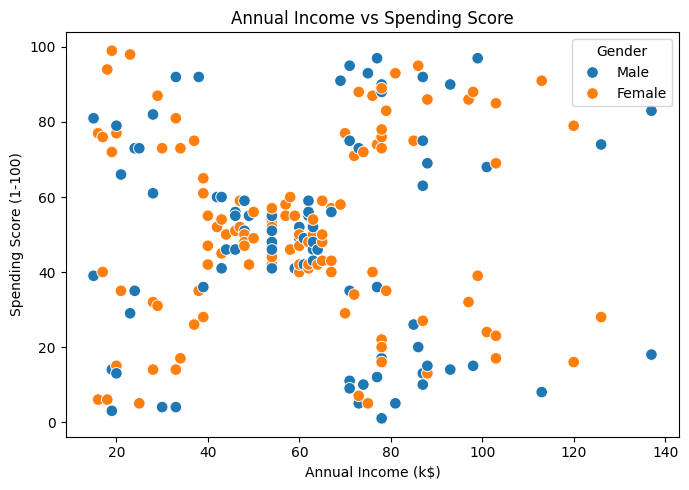

In [5]:

# Step 4: Explore customer data

# 1. Distribution of customer age
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Age", bins=15, kde=True)
plt.title("Age Distribution of Mall Customers")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# 2. Annual income vs spending score
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=70
)
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()


In [6]:

# Step 5: Select features for clustering

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Selected features:")
print(X.head())

print("\nScaled data shape:", X_scaled.shape)
print("\nFirst 5 scaled rows:")
print(X_scaled[:5])


Selected features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Scaled data shape: (200, 2)

First 5 scaled rows:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


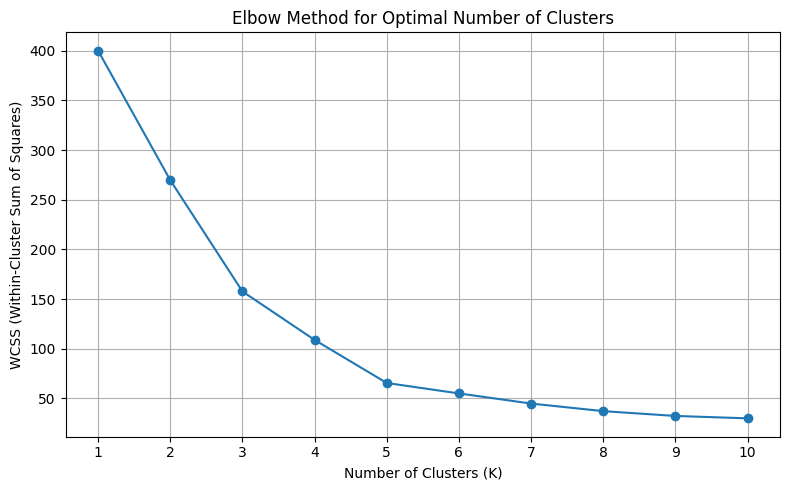

In [7]:

# Step 6: Find the optimal number of clusters using Elbow Method

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.xticks(range(1, 11))
plt.grid(True)
plt.tight_layout()
plt.show()


In [8]:

# Step 7: Apply K-Means clustering with 5 clusters

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed successfully!")

print("\nNumber of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nSample customer data with cluster labels:")
print(df[["Annual Income (k$)", "Spending Score (1-100)", "Cluster"]].head(10))


K-Means clustering completed successfully!

Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Sample customer data with cluster labels:
   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        2
2                  16                       6        4
3                  16                      77        2
4                  17                      40        4
5                  17                      76        2
6                  18                       6        4
7                  18                      94        2
8                  19                       3        4
9                  19                      72        2


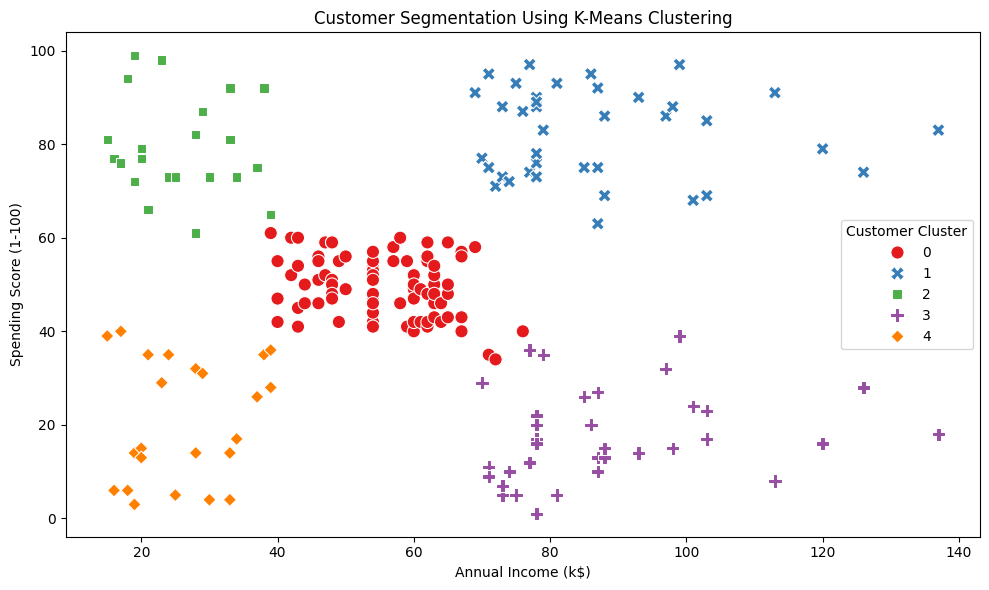

In [9]:

# Step 8: Visualize customer clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=90,
    style="Cluster"
)

plt.title("Customer Segmentation Using K-Means Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Cluster")
plt.tight_layout()
plt.show()


In [10]:

# Step 9: Analyze the characteristics of each cluster

cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("Customer Cluster Summary:")
display(cluster_summary)


Customer Cluster Summary:


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [11]:

# Step 11: Evaluate clustering using Silhouette Score

score = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", round(score, 3))


Silhouette Score: 0.555
